# Plot hexagons

In [1]:
!pwd



/net/home/swolf/Func_Neo_Phytes/notebooks/final_notebooks


In [2]:
# set working directory
import os
os.chdir("/net/home/swolf/Func_Neo_Phytes/")

### Load summary stats at hexagon level

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import h3pandas

In [4]:
summary_data = pd.read_csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree.csv")

summary_data.head()

,h3_res3,PC1_all,PC1_native,PC2_all,PC2_native,PC3_all,PC3_native,PC4_all,PC4_native,PC5_all,...,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,X.X4..n_na_all,X.X4..perc_na_all,X.X4..n_na_native,X.X4..perc_na_native,resolution
0,832830fffffffff,-1.723264,-1.278134,0.926335,0.167546,0.121624,0.599007,0.292163,0.465846,0.085470,...,0.468,0.430,0.461,-5.77,-6.72,108117,20.23,87976,23.23,h3_res3
1,832834fffffffff,-1.685929,-1.214233,0.457878,-0.273587,0.143289,0.638465,0.480214,0.635850,0.192815,...,0.477,0.449,0.471,-5.24,-4.67,83297,18.52,70916,21.17,h3_res3
2,832831fffffffff,-1.842768,-1.467624,0.789775,0.285863,0.670737,1.136367,0.017561,0.147281,-0.010408,...,0.460,0.437,0.458,-4.13,-4.59,14684,22.77,13393,25.91,h3_res3
3,832655fffffffff,-0.280022,0.031346,2.347101,2.208605,0.594250,1.044935,0.414081,0.314642,0.295809,...,0.446,0.435,0.438,-1.12,-0.68,2264,12.19,2178,14.93,h3_res3
4,832a16fffffffff,-0.848952,-0.321254,2.670935,2.316182,0.802047,1.815812,0.484026,0.651619,0.017235,...,0.440,0.406,0.426,-4.09,-4.69,5072,8.12,4484,11.52,h3_res3


## Calculate PC differences

In [7]:
# calculate differences between native and all for PC1 and PC2
summary_data['PC1_diff'] = summary_data['PC1_all'] - summary_data['PC1_native']
summary_data['PC2_diff'] = summary_data['PC2_all'] - summary_data['PC2_native']
summary_data['PC3_diff'] = summary_data['PC3_all'] - summary_data['PC3_native']
summary_data['PC4_diff'] = summary_data['PC4_all'] - summary_data['PC4_native']


### Create GeoDataFrame and Clean Geometries

This code block converts H3 hexagon indices to polygons, wraps longitudes to the range [-180, 180], and creates a GeoDataFrame. Invalid geometries and polygons spanning more than 180° longitude are removed to ensure clean and accurate spatial data for further analysis.




In [8]:
final_df = summary_data.copy()

In [9]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon
from shapely.ops import transform
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Function to convert H3 cell to polygon
def h3_to_polygon(h3_index):
    boundary = h3.h3_to_geo_boundary(h3_index, geo_json=True)
    return Polygon(boundary)

# Function to wrap longitudes to [-180, 180]
def wrap_geometry(geom):
    def wrap_coords(x, y):
        x_wrapped = ((x + 180) % 360) - 180
        return x_wrapped, y
    return transform(lambda x, y: wrap_coords(x, y), geom)

# Build geometry column
final_df["geometry"] = final_df["h3_res3"].apply(lambda x: wrap_geometry(h3_to_polygon(x)))

# Create GeoDataFrame
gdf = gpd.GeoDataFrame(final_df, geometry="geometry", crs="EPSG:4326")

# Fix column names
gdf.columns = gdf.columns.str.replace('.', '_')

# 💥 Remove invalid geometries and those spanning too much longitude
gdf = gdf[gdf.geometry.is_valid]  # remove invalid
gdf = gdf[gdf.bounds.maxx - gdf.bounds.minx < 180]  # remove polygons >180° wide


/tmp/ipykernel_4001941/3219989185.py:28: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  gdf.columns = gdf.columns.str.replace('.', '_')


### Plot world map 

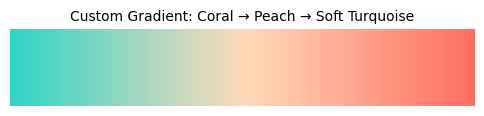

In [10]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Define your custom colors
colors = [ "#2ed5c9", "#FFDAB9", "#FF6F61"]

# Create the colormap
native_non_cmap = mcolors.LinearSegmentedColormap.from_list("custom_gradient", colors)

# OPTIONAL: Visualize it with a gradient bar
gradient = np.linspace(0, 1, 256).reshape(1, -1)

plt.figure(figsize=(6, 1))

plt.imshow(gradient, aspect='auto', cmap=native_non_cmap)
plt.axis("off")
plt.title("Custom Gradient: Coral → Peach → Soft Turquoise", fontsize=10)
plt.show()


In [11]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Define your colors
low_color = "#2F86AC"      # like native_color
mid_color = "white"
high_color = "#b02f2c"     # like all_color

# Create a custom diverging colormap
div_cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_diverging",
    [low_color, mid_color, high_color]
)


In [12]:
def plot_maps(gdf, pattern, output_suffix="meanbased_trim01_GBIF_wcvp_CS_log10_notrim_LCweighted"):
    
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    os.makedirs("Results/Figures", exist_ok=True)

    # Loop over columns matching the pattern
    for column in [col for col in gdf.columns if col.startswith(pattern)]:

        # -------------------------
        # Set colour scale
        # -------------------------

        if "percent_change" in column:
            vmin, vmax = -80, 80
            cmap = div_cmap

        elif "rank_biserial_r" in column:
            vmin, vmax = -0.7, 0.7
            cmap = div_cmap

        elif "perc_naturalized" in column:
            vmin, vmax = 0, 100
            cmap = "YlGnBu"

        elif "conifer_percentage" in column:
            vmin, vmax = 0, 20
            cmap = "YlGnBu"

        elif "annual_percentage" in column:
            vmin, vmax = 0, 40
            cmap = "YlGnBu_r"

        elif "PC1_diff" in column:
            vmin = np.nanpercentile(gdf[column], 5)
            vmax = np.nanpercentile(gdf[column], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC2_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC3_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC4_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif "PC5_diff" in column:
            vmin = np.nanpercentile(gdf["PC1_diff"], 5)
            vmax = np.nanpercentile(gdf["PC1_diff"], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif any(x in column for x in ["urban_diff", "nat_diff", "crop_diff"]):
            vmin, vmax = -1, 1
            cmap = div_cmap

        else:
            vmin = np.nanpercentile(gdf[column], 1)
            vmax = np.nanpercentile(gdf[column], 99)
            cmap = "YlGnBu"

        # -------------------------
        # Create map
        # -------------------------

        fig, ax = plt.subplots(
            figsize=(12, 10),
            subplot_kw={"projection": ccrs.EqualEarth()}
        )

        ax.set_global()

        ax.add_feature(
            cfeature.LAND,
            facecolor="#afafafff",
            edgecolor="none"
        )

        ax.add_feature(
            cfeature.OCEAN,
            facecolor="#dad8eaff",
            edgecolor="none"
        )

        ax._autoscaleXon = True
        ax._autoscaleYon = True

        # Plot hexagons
        gdf.plot(
            column=column,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            legend=True,
            ax=ax,
            transform=ccrs.PlateCarree(),
            linewidth=0.001,
            legend_kwds={"shrink": 0.45}
        )

        ax.set_title(
            f"{column} per hexagon",
            fontsize=12
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("#dad8eaff")
            spine.set_linewidth(0.7)

        plt.tight_layout()

        # -------------------------
        # Save
        # -------------------------

        output_path = (
            f"Results/Figures/"
            f"{column}_{output_suffix}.png"
        )

        plt.savefig(
            output_path,
            dpi=500,
            bbox_inches="tight"
        )
        print(output_path)
        plt.show()
        plt.close()

## Add Olsen Biome x Realm Regions

In [13]:
import geopandas as gpd
from os.path import expanduser

# Expand the user path and read the aggregated shapefile
wwf_aggregated = gpd.read_file(expanduser("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp"))


In [18]:
# read biome shift results
results = pd.read_csv("~/Func_Neo_Phytes/Results/quantification_shifts_regions_Olsen_GBIF_wcvp_CS_log10_notrim_misstree.csv")

In [19]:
# remove coluns that end with _PC4 and _PC5
results = results.loc[:, ~results.columns.str.endswith(('_PC4', '_PC5'))]
results

,region,biome_number,biome_name,realm_abbrev,realm_name,cliffs_delta_PC1,cliffs_delta_PC2,cliffs_delta_PC3,effect_size_PC1,effect_size_PC2,effect_size_PC3,significance_PC1,significance_PC2,significance_PC3
0,1_IM,1,Tropical & Subtropical Moist Broadleaf Forests,IM,Indomalaya,-0.217127,0.120380,-0.246734,small,small,small,***,**,***
1,1_NT,1,Tropical & Subtropical Moist Broadleaf Forests,NT,Neotropical,-0.020237,0.122341,-0.133989,negligible,small,small,NaN,**,***
2,2_AA,2,Tropical & Subtropical Dry Broadleaf Forests,AA,Australasia,0.305785,0.008264,-0.553719,medium,negligible,large,NaN,NaN,NaN
3,2_IM,2,Tropical & Subtropical Dry Broadleaf Forests,IM,Indomalaya,-0.297997,0.265479,-0.294615,medium,small,medium,**,**,***
4,2_NT,2,Tropical & Subtropical Dry Broadleaf Forests,NT,Neotropical,-0.040680,0.155141,-0.210614,negligible,small,small,NaN,NaN,*
5,4_AA,4,Temperate Broadleaf & Mixed Forests,AA,Australasia,-0.112233,0.379876,-0.307663,small,medium,medium,NaN,***,**
6,4_NA,4,Temperate Broadleaf & Mixed Forests,NaN,Nearctic,-0.175629,0.119317,-0.438602,small,small,large,**,NaN,***
7,4_NT,4,Temperate Broadleaf & Mixed Forests,NT,Neotropical,-0.131734,0.326392,-0.232232,small,medium,small,NaN,*,NaN
8,5_NA,5,Temperate Coniferous Forests,NaN,Nearctic,-0.048092,0.186711,-0.307441,negligible,small,medium,NaN,**,***
9,6_NA,6,Boreal Forests / Taiga,NaN,Nearctic,-0.005508,0.048500,-0.137018,negligible,negligible,small,NaN,NaN,*


In [21]:
# add column with realm extra (after the "_" in "bim_rlm")
wwf_aggregated['realm'] = wwf_aggregated['bim_rlm'].str.split('_').str[1]


In [22]:
# Simplify polygons with a lower tolerance value
wwf_aggregated['geometry'] = wwf_aggregated['geometry'].simplify(tolerance=0.001, preserve_topology=True)

# add buffer around polygons
wwf_aggregated['geometry'] = wwf_aggregated['geometry'].buffer(1)

/tmp/ipykernel_4001941/816051289.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  wwf_aggregated['geometry'] = wwf_aggregated['geometry'].buffer(1)


In [23]:
def plot_hex_maps_with_biomes(
    gdf,
    pattern,
    results,
    wwf_aggregated,
    div_cmap,
    output_suffix="map",
    pc_axes=None,
):
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    os.makedirs("Results/Figures", exist_ok=True)

    # ── Pre-process wwf_aggregated (once, on a copy) ──────────────────────────
    wwf = wwf_aggregated.copy()
    wwf["realm"] = wwf["bim_rlm"].str.split("_").str[1]
    wwf["geometry"] = wwf["geometry"].simplify(tolerance=0.001, preserve_topology=True)
    wwf["geometry"] = wwf["geometry"].buffer(1)

    # ── Dissolve all regions once for the background outline ─────────────────
    all_regions = wwf.dissolve(by="bim_rlm")

    # ── Infer available PC axes from results columns ──────────────────────────
    if pc_axes is None:
        pc_axes = sorted([
            int(col.replace("significance_PC", ""))
            for col in results.columns
            if col.startswith("significance_PC")
        ])

    # ── Pre-compute significant bim_rlm values per axis ──────────────────────
    sig_realms = {}
    for ax in pc_axes:
        col = f"significance_PC{ax}"
        if col in results.columns:
            sig_realms[ax] = results.loc[results[col].notna(), "bim_rlm"].tolist()
        else:
            sig_realms[ax] = []

    # ── Helper: infer which PC axis a column belongs to ──────────────────────
    def _get_pc_axis(column):
        for ax in pc_axes:
            if f"PC{ax}_diff" in column or f"PC{ax}_" in column:
                return ax
        return None

    # ── Loop over matching columns ────────────────────────────────────────────
    for column in [col for col in gdf.columns if col.startswith(pattern)]:

        # ── Colour scale ─────────────────────────────────────────────────────
        if "percent_change" in column:
            vmin, vmax = -80, 80
            cmap = div_cmap

        elif "rank_biserial_r" in column:
            vmin, vmax = -0.7, 0.7
            cmap = div_cmap

        elif "perc_naturalized" in column:
            vmin, vmax = 0, 100
            cmap = "YlGnBu"

        elif "conifer_percentage" in column:
            vmin, vmax = 0, 20
            cmap = "YlGnBu"

        elif "annual_percentage" in column:
            vmin, vmax = 0, 40
            cmap = "YlGnBu_r"

        elif any(f"PC{ax}_diff" in column for ax in pc_axes):
            ref_col = "PC1_diff"
            vmin = np.nanpercentile(gdf[ref_col], 5)
            vmax = np.nanpercentile(gdf[ref_col], 95)
            limit = max(abs(vmin), abs(vmax))
            vmin, vmax = -limit, limit
            cmap = div_cmap

        elif any(x in column for x in ["urban_diff", "nat_diff", "crop_diff"]):
            vmin, vmax = -1, 1
            cmap = div_cmap

        else:
            vmin = np.nanpercentile(gdf[column], 1)
            vmax = np.nanpercentile(gdf[column], 99)
            cmap = "YlGnBu"

        # ── Figure ───────────────────────────────────────────────────────────
        fig, ax = plt.subplots(
            figsize=(12, 10),
            subplot_kw={"projection": ccrs.EqualEarth()}
        )
        ax.set_global()
        ax.add_feature(cfeature.LAND,  facecolor="#afafafff", edgecolor="none")
        ax.add_feature(cfeature.OCEAN, facecolor="#dad8eaff", edgecolor="none")
        ax._autoscaleXon = True
        ax._autoscaleYon = True

        # ── Hexagons ─────────────────────────────────────────────────────────
        gdf.plot(
            column=column,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            legend=True,
            ax=ax,
            transform=ccrs.PlateCarree(),
            linewidth=0.001,
            legend_kwds={"shrink": 0.45},
        )

        # ── Biome outlines: all realms (thin, background reference) ──────────
        #regions = wwf_aggregated.dissolve(by='realm')
        all_regions.plot(
            ax=ax,
            facecolor="none",
            edgecolor="#045A7F55",
            linewidth=0.6,
            transform=ccrs.PlateCarree(),
        )

        # ── Biome outlines: significant realms only (bold) ───────────────────
        pc_ax = _get_pc_axis(column)
        if pc_ax is not None and sig_realms.get(pc_ax):
            sig = all_regions.loc[
                all_regions.index.isin(sig_realms[pc_ax])
            ]
            if not sig.empty:
                sig.plot(
                    ax=ax,
                    facecolor="none",
                    edgecolor="#045A7FFF",
                    linewidth=2.0,
                    transform=ccrs.PlateCarree(),
                )

        # ── Styling ──────────────────────────────────────────────────────────
        ax.set_title(f"{column} per hexagon", fontsize=12)
        for spine in ax.spines.values():
            spine.set_edgecolor("#dad8eaff")
            spine.set_linewidth(0.7)

        plt.tight_layout()

        # ── Save ─────────────────────────────────────────────────────────────
        output_path = f"Results/Figures/{column}_{output_suffix}.png"
        plt.savefig(output_path, dpi=500, bbox_inches="tight")
        print(output_path)
        plt.show()
        plt.close()

## Plot maps

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

Results/Figures/PC1_diff_meanbased_GBIF_wcvp_CS_log10_notrim_misstree.png


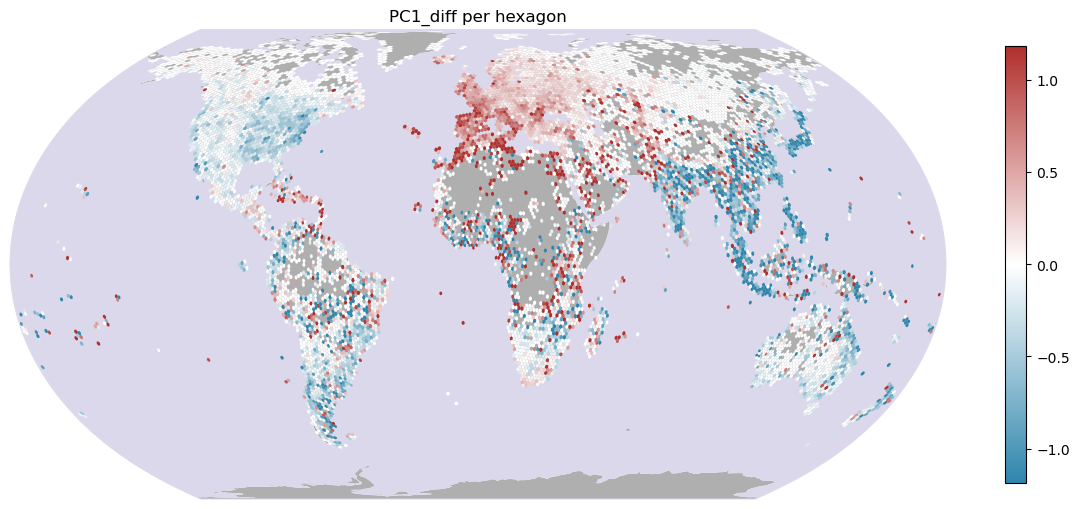

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC2_diff_meanbased_GBIF_wcvp_CS_log10_notrim_misstree.png


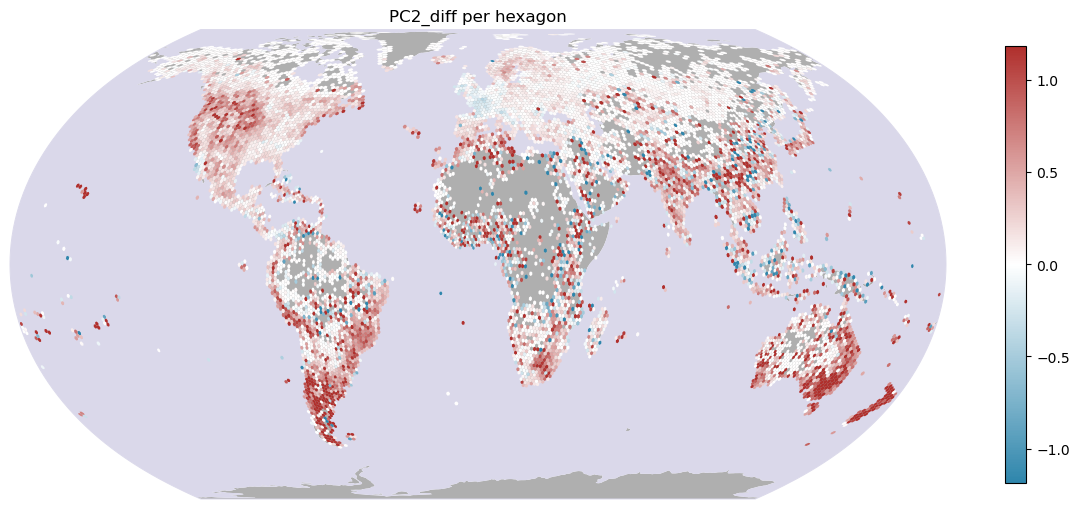

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC3_diff_meanbased_GBIF_wcvp_CS_log10_notrim_misstree.png


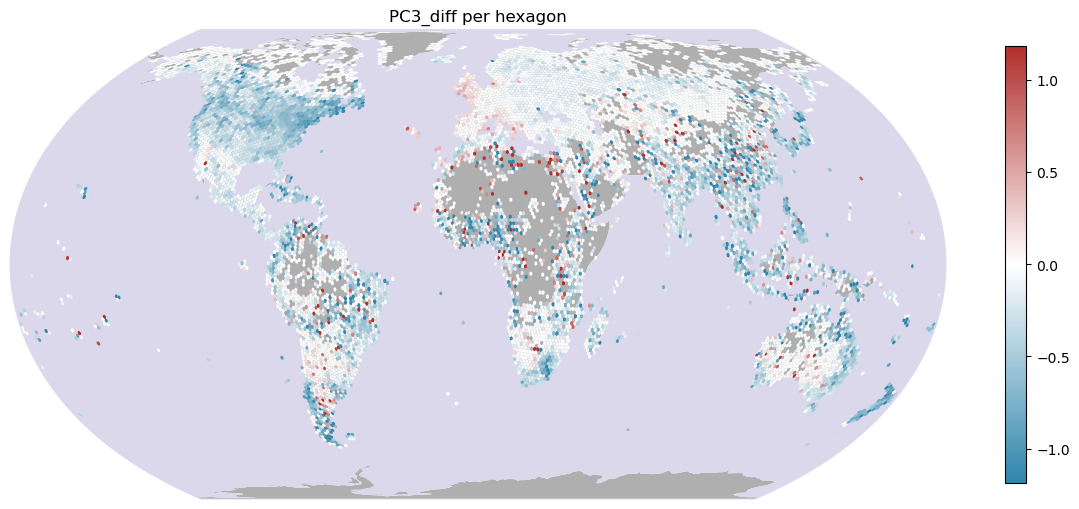

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


Results/Figures/PC4_diff_meanbased_GBIF_wcvp_CS_log10_notrim_misstree.png


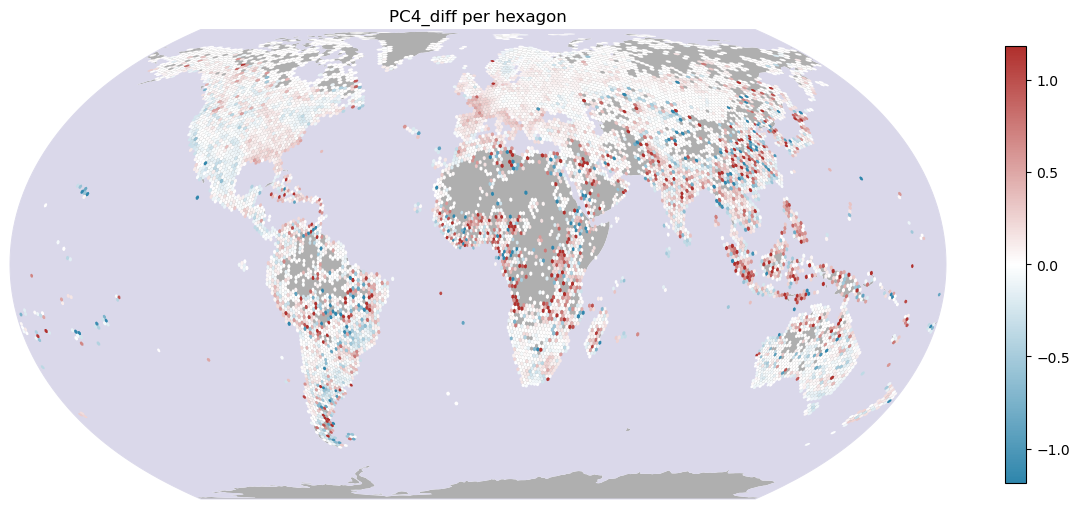

In [24]:
# Plot differeces in PC space for PC1, PC2, and PC3
plot_maps(gdf, "PC1_diff", output_suffix="meanbased_GBIF_wcvp_CS_log10_notrim_misstree")
plot_maps(gdf, "PC2_diff", output_suffix="meanbased_GBIF_wcvp_CS_log10_notrim_misstree")
plot_maps(gdf, "PC3_diff", output_suffix="meanbased_GBIF_wcvp_CS_log10_notrim_misstree")
plot_maps(gdf, "PC4_diff", output_suffix="meanbased_GBIF_wcvp_CS_log10_notrim_misstree")
plot_maps(gdf, "PC5_diff", output_suffix="meanbased_GBIF_wcvp_CS_log10_notrim_misstree")

## Biome overview map

In [ ]:
import geopandas as gpd
from os.path import expanduser

# Expand the user path and read the aggregated shapefile
wwf_aggregated = gpd.read_file(expanduser("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp"))


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

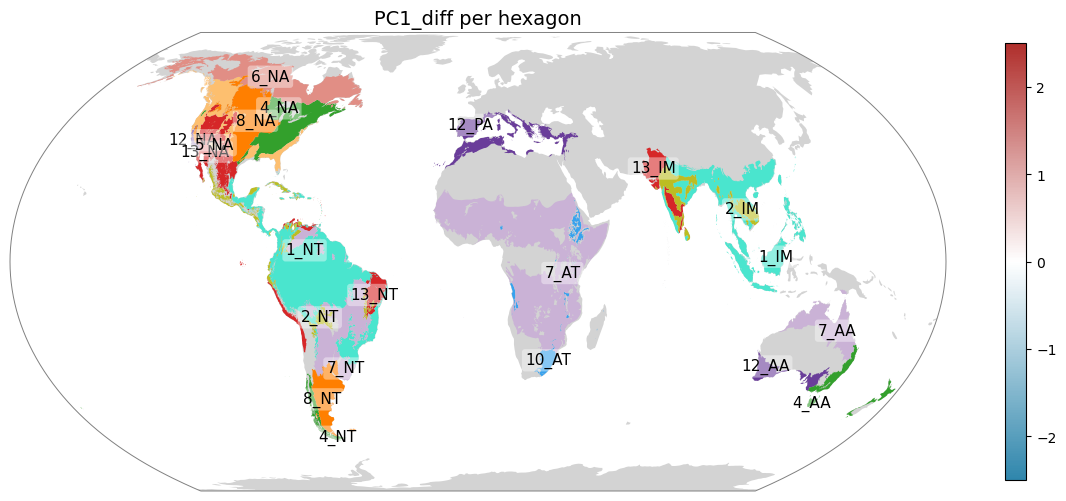

In [ ]:
import os
import numpy as np
from matplotlib import colormaps


#pattern = "perc_"
#pattern = "count_"
#pattern = "X"
pattern = "PC1_diff"
#pattern = "PC1_all"
#pattern = "PC2_percent_change"


# Ensure the results directory exists
os.makedirs("Results/Figures", exist_ok=True)

# Loop over all columns that start with "X"
for column in [col for col in gdf.columns if col.startswith(pattern)]: 
#for column in [col for col in gdf.columns if "percent_change" in col]:
#for column in [col for col in gdf.columns if col.endswith("percent_change_median")]:
#for column in [col for col in gdf.columns if col.endswith("p_value")]:
#for column in [col for col in gdf.columns if col.endswith("rank_biserial_r")]:

    if "percent_change" in column:
        vmin, vmax = -80, 80
        cmap = div_cmap
    elif "rank_biserial_r" in column:
        vmin, vmax = -0.7, 0.7
        cmap = div_cmap
    elif "perc_naturalized" in column:
        cmap = "YlGnBu"
        vmin, vmax = 0, 100
    elif "PC1_diff" in column:
        vmin, vmax = -2.5, 2.5
        cmap = div_cmap
    elif "PC2_diff" in column:
        vmin, vmax = -2.5, 2.5
        cmap = div_cmap
    else:
        vmin = np.nanpercentile(gdf[column], 1)
        vmax = np.nanpercentile(gdf[column], 99)
        cmap = "YlGnBu"
        
    # Create plot with Robinson projection
    fig, ax = plt.subplots(figsize=(12, 10), subplot_kw={'projection': ccrs.EqualEarth()})
    #fig, ax = plt.subplots(figsize=(32, 18), subplot_kw={'projection': ccrs.EqualEarth()})
    
    ax.set_global()
    #ax.add_feature(cfeature.LAND, facecolor='#2F86AC', edgecolor='none')
    ax.add_feature(cfeature.LAND, facecolor='lightgrey', edgecolor='none')
    #ax.add_feature(cfeature.LAND, facecolor='#A7AE9C', edgecolor='none')
    
    ax._autoscaleXon = True
    ax._autoscaleYon = True


    # Plot hexagons
    gdf.plot(
        column=column,
        cmap=cmap,
        vmin = vmin,
        vmax = vmax,
        legend=True,
        ax=ax,
        transform=ccrs.PlateCarree(),
        #edgecolor="black",
        linewidth=0,
        alpha=0,
        legend_kwds={"shrink": 0.45}
    )

    ax.set_title(f"{column} per hexagon", fontsize=14)
    #ax.set_title(f"Community science observations: {column} per hexagon", fontsize=14)
    #ax.set_title(f"GBIF sample (min. 1, max. 5000): Percent naturalized per hexagon", fontsize=14)
    
    #add coastlines
    #ax.coastlines(resolution='110m', color='#2F86AC', linewidth=0.7)
    #ax.coastlines(resolution='110m', color='pink', linewidth=0.9)
    #ax.coastlines(resolution='110m', color='pink', linewidth=2)
    
    for spine in ax.spines.values():
        spine.set_edgecolor("grey")       # Color of the frame
        spine.set_linewidth(0.7)           # Thickness of the frame
        #spine.set_linewidth(2)

    # Filter and plot region polygons (excluding oceans)
    # PC1 significant regions
    #sig_regions =[ "12_PA", "1_IM",  "2_IM",  "4_NA",  "8_NA",  "8_NT",  "8_PA" ]
    
    # PC2 significant regions
    #sig_regions = ["13_IM", "1_IM",  "2_IM",  "4_AA",  "4_NT",  "5_NA",  "7_AA",  "8_NA",  "8_NT" ]

    sig_regions = [
        "12_PA", "1_IM", "2_IM", "4_NA", "10_AT", "12_AA", "12_NA", "13_IM",
        "13_NA", "1_NT", "4_AA", "4_NT", "5_NA", "7_AA", "7_AT", "7_NT",
        "8_NA", "8_NT", "13_NT", "2_NT", "6_NA"
    ]


    regions = wwf_aggregated[wwf_aggregated["bim_rlm"].isin(sig_regions)]
    
    # color for each region based on all_regions
    
    # Ensure no NaN values in the color mapping
    facecolor_mapping = regions["bim_rlm"].map({
        "10_AT": "#37a2ee",
        "12_NA": "#6a3d9a",
        "12_PA": "#6a3d9a",
        "12_AA": "#6a3d9a",
        "13_IM": "#d62728",
        "13_NA": "#d62728",
        "13_NT": "#d62728",
        "1_IM": "#4ae5ce",
        "1_NT": "#4ae5ce",
        "2_IM": "#bcbd22",
        "2_NT": "#bcbd22",
        "4_AA": "#33a02c",
        "4_NA": "#33a02c",
        "4_NT": "#33a02c",
        "5_NA": "#fdbf6f",
        "6_NA": "#e18e85",
        "7_AA": "#cab2d6",
        "7_NT": "#cab2d6",
        "7_AT": "#cab2d6",
        "8_NA": "#ff7f00",
        "8_NT": "#ff7f00",
        "8_PA": "#ff7f00",
    }).fillna("#d3d3d3")  # Default to light grey for unmapped regions


    regions.plot(
        ax=ax,
        facecolor=facecolor_mapping,
        linewidth=0.8,
        transform=ccrs.PlateCarree()
    )

    # Add region acronyms (optional)
    for idx, row in regions.iterrows():
        point = row.geometry.representative_point()
        ax.text(
            point.x, point.y, row["bim_rlm"],
            fontsize=11,
            ha="center", va="center",
            transform=ccrs.PlateCarree(),
            color="black",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.4, boxstyle="round,pad=0.2")
        )

    plt.tight_layout()
    
    # Save the plot
    output_path = f"Results/Figures/{column}_meanbased_trim01_GBIF_wcvp_CS_Olsen_plain_log10.png"
    #plt.savefig(output_path, format="pdf")
    plt.savefig(output_path, dpi=500, bbox_inches='tight')
    
    # Show the plot
    plt.show()

    